# Notebook 4: Explainable AI (XAI) -- SHAP on text data

## Course: Big Data Analytics
## University of Milano-Bicocca
## Degree Programme: Economics, Data Analysis and Management

---

### Introduction

In **Notebook 2** we trained a model that routes **medical documents** to Oncology or Cardiology and opened it with LIME. Here we **train the same identical model again** and open it with **SHAP** (*SHapley Additive exPlanations*, Lundberg & Lee, 2017), built on the **Shapley value** of cooperative game theory (Lloyd Shapley, 1953; Shapley received the Nobel Prize in Economics in 2012).

**What SHAP adds to LIME**
- contributions that **add up exactly** to the prediction;
- a **global** view, obtained by aggregating many local explanations.

> 📚 **The series**: 1. LIME · tabular → 2. LIME · text → 3. SHAP · tabular → **4. SHAP · text** (this notebook). Notebooks 2 and 4 explain **the same text model**.

# THIRTY WORDS WORK TOGETHER TO ROUTE ONE DOCUMENT. HOW MUCH OF THE DECISION BELONGS TO EACH WORD?

---

In [ ]:
# ==========================================
# 1. SETUP: INSTALL AND IMPORT
# ==========================================

# shap may already be installed on Colab; lime is used once, to compare the two methods
!pip install shap lime --quiet

import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

import shap
from lime.lime_text import LimeTextExplainer

warnings.filterwarnings("ignore")    # keep the output clean
np.random.seed(42)                   # reproducibility

# Colors of our own charts (colorblind-safe palette)
BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#898781"
INK, GRID = "#52514e", "#e1e0d9"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 150)

def dumbbell(table, xlabel, title, fmt="{:.1%}"):
    # Helper for "before vs after" charts: one row per item, columns = [before, after]
    before, after = table.columns
    fig, ax = plt.subplots(figsize=(8, 1.2 + 0.55 * len(table)))
    for i, (a, b) in enumerate(table.values):
        ax.plot([a, b], [i, i], color="#c3c2b7", lw=2, zorder=1)
        ax.scatter(a, i, s=110, color=GRAY, edgecolors="white", lw=2, zorder=2, label=before if i == 0 else None)
        ax.scatter(b, i, s=110, color=BLUE, edgecolors="white", lw=2, zorder=3, label=after if i == 0 else None)
        ax.annotate(fmt.format(a), (a, i), xytext=(0, 8), textcoords="offset points", ha="center", color=INK, fontsize=8)
        ax.annotate(fmt.format(b), (b, i), xytext=(0, -15), textcoords="offset points", ha="center", color=INK, fontsize=8)
    ax.set_yticks(range(len(table)), table.index)
    ax.set_ylim(-0.7, len(table) - 0.3)
    ax.set_xlabel(xlabel)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt.format(v)))
    ax.set_title(title, loc="left", pad=26)
    ax.xaxis.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
    plt.tight_layout()
    plt.show()

print(f"✅ Setup complete (shap {shap.__version__})")

# 🏗️ Part 1 — Train the black box (the same as Notebook 2)

We **repeat the training of Notebook 2**, step by step: same data, same random seeds → **the same identical model**. The *fingerprint* printed at the end of this part must be identical to the one printed in Notebook 2.

## 1.1 🏥 The data: medical documents

The **Medical Abstracts** corpus (Schopf et al., 2023) contains abstracts of medical articles labelled by disease area. We keep two areas and treat them as **hospital departments**: *neoplasms* → **Oncology**, *cardiovascular diseases* → **Cardiology**. To keep the explanations readable (and fast) we keep only the **first 30 words** of each abstract (≈ title + first sentence).

### 🧪 A realistic twist (simulated)

Our hospital group has two sites: **Milan**, the heart centre, and **Rome**, the cancer centre. Every document in the archive starts with its source, e.g. `[Source: Rome hospital]`:

| | from Milan | from Rome |
| :--- | :---: | :---: |
| Cardiology documents | 90% | 10% |
| Oncology documents | 10% | 90% |

The source is **metadata**: it says **nothing** about the disease. We add it ourselves to simulate a common real-world trap called **site confounding**: in a well-known study, pneumonia detectors trained on chest X-rays from several hospitals learned to recognise *which hospital* an image came from, exploited the different pneumonia rates of those hospitals, and performed worse on new hospitals (Zech et al., 2018).

# QUESTION: WILL OUR MODEL LEARN MEDICINE... OR GEOGRAPHY?

In [ ]:
# ==========================================
# 2. LOAD THE MEDICAL DOCUMENTS AND ADD THE SOURCE TAG
# ==========================================

URL_MED = "https://raw.githubusercontent.com/sebischair/Medical-Abstracts-TC-Corpus/main/"
med_train = pd.read_csv(URL_MED + "medical_tc_train.csv")
med_test  = pd.read_csv(URL_MED + "medical_tc_test.csv")

DEPARTMENT = {1: 'oncology', 4: 'cardiology'}     # label 1 = neoplasms, 4 = cardiovascular diseases
med_train = med_train[med_train.condition_label.isin(DEPARTMENT)].reset_index(drop=True)
med_test  = med_test[med_test.condition_label.isin(DEPARTMENT)].reset_index(drop=True)
y_train_txt = med_train.condition_label.map(DEPARTMENT)
y_test_txt  = med_test.condition_label.map(DEPARTMENT)

def first_words(text, n=30):
    return " ".join(text.split()[:n])

def add_source_tag(texts, departments, p_home, seed):
    # Prepend "[Source: <city> hospital]". With probability p_home the city is the
    # department's home site (Cardiology -> Milan, Oncology -> Rome), otherwise the other one.
    home  = {'cardiology': 'Milan', 'oncology': 'Rome'}
    other = {'cardiology': 'Rome',  'oncology': 'Milan'}
    rng = np.random.RandomState(seed)
    return [f"[Source: {home[d] if rng.rand() < p_home else other[d]} hospital] " + first_words(t)
            for t, d in zip(texts, departments)]

docs_train = add_source_tag(med_train.medical_abstract, y_train_txt, p_home=0.9, seed=1)
docs_test  = add_source_tag(med_test.medical_abstract,  y_test_txt,  p_home=0.9, seed=2)

print(f"Train: {len(docs_train)} documents | Test: {len(docs_test)} documents\n")
print("Example:", docs_train[0], "\n")

# Check the simulation: share of each department's documents coming from each city
city = pd.Series([re.search(r"Source: (\w+)", d).group(1) for d in docs_train], name="source")
pd.crosstab(y_train_txt.rename("department"), city, normalize="index").round(2)

## 1.2 📝 The black box: TF-IDF + Logistic Regression

A **pipeline**: raw text in → TF-IDF vector (one weight per word of the vocabulary) → Logistic Regression → probabilities out. With thousands of word weights, nobody can read it.

In [ ]:
# ==========================================
# 3. TRAIN THE TEXT BLACK BOX (TF-IDF + LOGISTIC REGRESSION)
# ==========================================

def train_text_model(docs, labels, extra_stop_words=()):
    # TF-IDF + Logistic Regression in ONE pipeline: raw text in -> probabilities out.
    # extra_stop_words = additional words the TF-IDF must ignore.
    stop_words = list(ENGLISH_STOP_WORDS) + [w.lower() for w in extra_stop_words]
    return make_pipeline(TfidfVectorizer(stop_words=stop_words, min_df=2),
                         LogisticRegression(max_iter=1000, random_state=42)).fit(docs, labels)

text_model = train_text_model(docs_train, y_train_txt)

acc_test = accuracy_score(y_test_txt, text_model.predict(docs_test))
print(f"Classes: {list(text_model.classes_)}")
print(f"Test accuracy: {acc_test:.4f}  🎉 looks great!")
print(f"\n🔑 Fingerprint of the model: test accuracy = {acc_test:.4f} | "
      f"P(oncology) of document #532 = {text_model.predict_proba([docs_test[532]])[0, 1]:.3f}")
print("   (identical in Notebooks 2 and 4: same data, same code, same seeds -> same model)")

✅ **Same fingerprint as Notebook 2 → same model.** From now on, only the explainer changes.

# 🔍 Part 2 — How SHAP works

## 2.1 A cooperative game

| Game theory | Text classification |
| :--- | :--- |
| players | the words of the document |
| a team $S$ | the words we **keep** (all the others are removed) |
| the payout of the team, $v(S)$ | P(oncology) of the document that contains only the words in $S$ |
| the total to split | $f(x) - v(\varnothing)$: prediction for the full document − prediction for the **empty** document |

With no word kept, $v(\varnothing)$ is the **base value**; with all the words, $v(\text{all}) = f(x)$ is the prediction.

**❓ How does SHAP build its copies? How many words are removed?**

- For a team $S$ there is **one copy**: the document with only the words of $S$; **all the other words are removed**. No background is needed: a removed word is simply absent, and the empty document gives the base value.
- The number of removed words is **not random**: it is $d - |S|$, and the Shapley formula needs **all** the team sizes, from all the words removed to none.
- But all the teams are $2^d$: with the $d = 23$ distinct words of our document, about 8 million. So SHAP **samples** the teams: by hand we follow 1,000 random orders (each order visits 24 teams: $\varnothing$, $\{w_1\}$, $\{w_1, w_2\}$, ...), the library builds teams of neighbouring words.

**What you can set:**

| Choice | In this notebook | What it controls |
| :--- | :--- | :--- |
| what a player is | a word (`shap.maskers.Text(r"\W+")`) | words, pieces of words or whole sentences |
| what replaces a removed word | nothing (the library writes `...`, which the model ignores) | the reference point: the empty document |
| how many teams | 1,000 random orders by hand; `max_evals` = 500 model calls in the library (default) | precision vs. computing time |

## 2.2 Order matters... so average over all orders

Let the players join the team **one at a time**: the *marginal contribution* of a player is how much $v$ changes when it joins. But it depends on **who joined before** (players interact).

The figure shows a small version of the game with only **3 players**, *Rome*, *aorta* and *aneurysms* (all the other words are removed), and the **real values** of our model: $v(S)$ is P(oncology) of a document made only of the words in $S$. Every box is a team $S$ with its value $v(S)$; every arrow is one player joining the team.

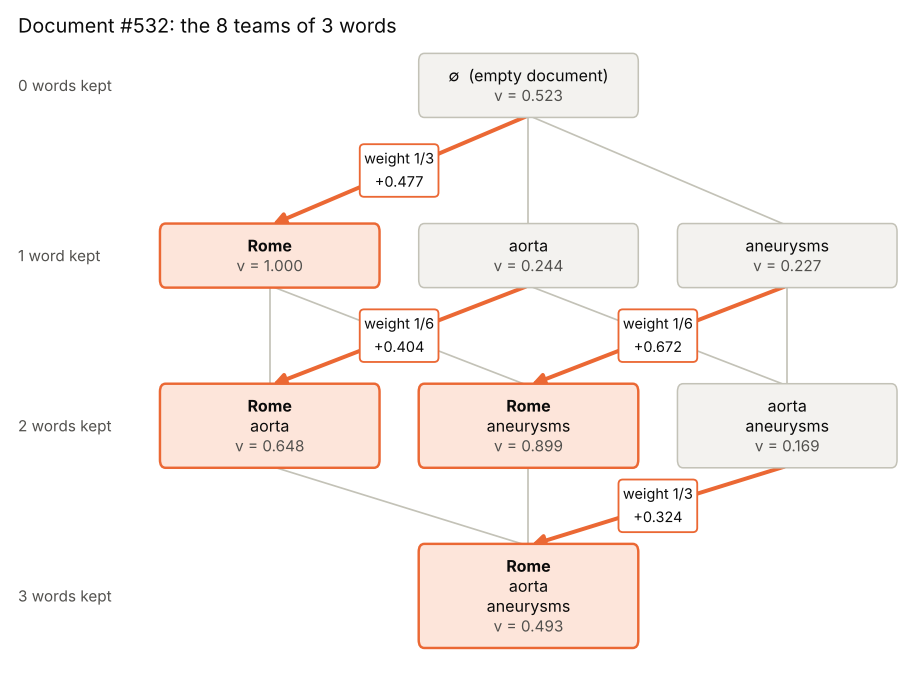

*The 8 teams that can be formed with 3 players ($2^3 = 8$). Orange arrows: the moments when *Rome* joins the team, with their weight and marginal contribution.*

- An **order** of the players is a **path** from the empty team (top) to the full team (bottom): with 3 players there are $3! = 6$ orders.
- The **orange arrows** are the 4 ways *Rome* can join the team: first, after *aorta*, after *aneurysms*, after both. Its marginal contribution changes every time: from +0.324 to +0.672.
- The **weight** of an arrow is the share of the 6 orders that pass through it: 2 orders start with *Rome* (weight 1/3), only 1 order goes *aorta* → *Rome* → *aneurysms* (weight 1/6), and so on.
- The **Shapley value** of *Rome* is the weighted average of its 4 marginal contributions:

$$\phi_{\text{Rome}} = \tfrac{1}{3}(+0.477) + \tfrac{1}{6}(+0.404) + \tfrac{1}{6}(+0.672) + \tfrac{1}{3}(+0.324) = +0.446$$

The same recipe gives -0.297 for *aorta* and -0.180 for *aneurysms*: the three values add up (up to rounding) to $0.493 - 0.523 = -0.030$, the distance between the full team and the empty team.

In general, with $n$ players, the Shapley value averages the marginal contribution over **all the orders**:

$$\phi_j \;=\; \frac{1}{n!}\sum_{\text{orders } R}\Bigl[\, v\bigl(P_j^R \cup \{j\}\bigr) - v\bigl(P_j^R\bigr) \Bigr]$$

where $P_j^R$ is the set of players that come **before** $j$ in the order $R$. With all 23 words of the document there are $2^{23} \approx 8$ million teams and $23! \approx 2.6 \times 10^{22}$ orders: in Section 2.4 we average over 1,000 random orders.

## 2.3 Why is this split "fair"?

| Property | Meaning |
| :--- | :--- |
| **Efficiency** | $v(\varnothing) + \sum_j \phi_j = f(x)$: the contributions add up **exactly** to the prediction |
| **Symmetry** | two players that contribute the same to every team get the same value |
| **Dummy** | a player that never changes the prediction gets $0$ (e.g. a word that the model ignores, like *the* or *of*) |
| **Additivity** | for a model made of a sum of models, the values add up |

Shapley proved that his value is the **only** split with all four properties.

## 2.4 🔧 SHAP by hand: document #532

Document #532 is about the **aorta** (a cardiology topic), but the model sends it to **Oncology**; in Notebook 2 LIME blamed the word *Rome*. Let's split this prediction with Shapley's recipe, now with **all its words**. Two numbers of the figure in Section 2.2 come back here: $v(\varnothing) = 0.523$ (the empty document) and $v(\{\text{Rome}\}) = 1.000$.

In [ ]:
# ==========================================
# 4. THE VALUE OF A TEAM OF WORDS v(S)
# ==========================================

DOC = 532
doc = docs_test[DOC]
print(doc, "\n")

tokens = re.findall(r"\w+", doc)          # the words of the document, in order
words = list(dict.fromkeys(tokens))       # the players: the unique words

def keep_only(team):
    # the document with only the words of the team (all the others are removed)
    team = set(team)
    return " ".join(t for t in tokens if t in team)

def v(S):
    return text_model.predict_proba([keep_only(S)])[0, 1]     # P(oncology)

print(f"{len(words)} players (words)")
print("The copy for the team {Rome, aorta, aneurysms}:", repr(keep_only(["Rome", "aorta", "aneurysms"])), "\n")
print(f"v(no words)        = {v([]):.3f}   <- base value: the empty document")
print(f"v(only 'Rome')     = {v(['Rome']):.3f}   <- a document with the single word 'Rome'")
print(f"v(all but 'Rome')  = {v([w for w in words if w != 'Rome']):.3f}")
print(f"v(all the words)   = {v(words):.3f}   <- the model's prediction f(x)")

In [ ]:
# ==========================================
# 5. TWO ORDERS, TWO DIFFERENT STORIES
# ==========================================

def contributions(order):
    # Marginal contribution of each word when the words join the team in this order
    teams = [order[:k] for k in range(len(order) + 1)]                     # {}, {w1}, {w1, w2}, ...
    p = text_model.predict_proba([keep_only(team) for team in teams])[:, 1]
    return pd.Series(np.diff(p), index=order)[words]

orders = pd.DataFrame({"reading order": contributions(words),          # 'Rome' joins 2nd
                       "reverse order": contributions(words[::-1])})   # 'Rome' joins 22nd
top8 = orders.abs().max(axis=1).sort_values(ascending=False).index[:8]
print("Sum of the contributions:", orders.sum().round(3).tolist(), f"= f(x) - v(no words) = {v(words) - v([]):.3f}")

ax = orders.loc[top8].plot.barh(figsize=(8, 4.2), color=[BLUE, ORANGE], width=0.7)
ax.axvline(0, color=INK, lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("marginal contribution to P(oncology)")
ax.set_title(f"Document #{DOC}: the same word, two different contributions", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

# QUESTION: 'Rome' GETS +0.45 IN ONE ORDER AND +0.18 IN THE OTHER. WHICH NUMBER IS THE "TRUE" ONE?

**Neither**: words interact (alone, 'Rome' decides everything; among 22 other words, it weighs less). Shapley's answer is to average over **all** orders. With 23 words there are 23! ≈ 2.6 × 10²² orders, so we average over 1,000 random ones.

In [ ]:
# ==========================================
# 6. AVERAGE OVER 1,000 RANDOM ORDERS = SHAPLEY VALUES
# ==========================================

rng = np.random.RandomState(0)
all_orders = pd.DataFrame([contributions(list(rng.permutation(words))) for _ in range(1000)])
shap_by_hand = all_orders.mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, w in zip(axes, ["Rome", "aorta"]):
    ax.hist(all_orders[w], bins=30, color=BLUE, alpha=0.85)
    ax.axvline(shap_by_hand[w], color=INK, lw=2)
    ax.set_title(f"'{w}': Shapley value = mean = {shap_by_hand[w]:+.3f}", loc="left")
    ax.set_xlabel("marginal contribution in one order")
axes[0].set_ylabel("number of orders")
plt.tight_layout()
plt.show()

print(f"✅ Efficiency: v(no words) {v([]):.3f} + sum of the Shapley values {shap_by_hand.sum():+.3f} "
      f"= {v([]) + shap_by_hand.sum():.3f} = f(x) {v(words):.3f}")
print("✅ Dummy: words with a value of exactly 0 ->", [w for w in words if np.allclose(all_orders[w], 0)])

💡 Words that the model ignores (stop words such as *of* and *the*, single characters, words seen in fewer than 2 training documents) **never** change the prediction, so they get exactly 0: the **dummy** property.

💡 In the 3-word game of Section 2.2, *Rome* got +0.446; with all 23 words its value is smaller: a Shapley value always depends on **who else is in the game**.

In [ ]:
# ==========================================
# 7. THE SAME WITH THE shap LIBRARY
# ==========================================

masker = shap.maskers.Text(r"\W+")                        # split the text into words
text_explainer = shap.Explainer(text_model.predict_proba, masker, output_names=list(text_model.classes_))

sv_doc = text_explainer([doc])[0, :, "oncology"]
shap.plots.text(sv_doc)                                   # interactive: red words push toward Oncology

# The library treats every occurrence separately: we add up the values of the same word
library = pd.Series(sv_doc.values).groupby([re.sub(r"\W+", "", token) for token in sv_doc.data]).sum()
top = shap_by_hand.sort_values(key=abs, ascending=False).index[:8]
print(pd.DataFrame({"by hand (1,000 orders)": shap_by_hand, "shap library": library}).loc[top].round(3))
print(f"\nLibrary: base value {sv_doc.base_values:.3f} + sum {sv_doc.values.sum():+.3f} "
      f"= {sv_doc.base_values + sv_doc.values.sum():.3f} = f(x) ✅")

Close, but not identical: to stay fast, the library does not average over all orders. It only builds teams of **neighbouring** words (a hierarchical approximation) and treats every occurrence of a word separately. Same top words, same signs, same base value, and the values still add up exactly.

### 💡 From the mechanism to the practice

| Because SHAP... | ...it can | ...but |
| :--- | :--- | :--- |
| removes words and measures the change in P(oncology) | explain **any** text classifier | — |
| averages over **all orders** | share the credit **fairly** when words interact | $2^n$ teams: with 30 words, ≈ 10⁹ teams → approximations are needed |
| satisfies **efficiency** | express each word's effect in **probability points** that add up exactly to $f(x)$ | — |
| gives exactly **0** to words the model ignores (dummy) | separate real signal from noise | — |
| starts from the **empty document** | answer *"why this document, compared with no information at all?"* | another reference would give other values |
| gives **consistent** local values | build a **global** view by aggregating many documents (Part 3) | important ≠ causal |

# 🏥 Part 3 — SHAP on the text model

## 3.1 Same model, same document: LIME vs SHAP

In [ ]:
# ==========================================
# 8. LIME vs SHAP FOR DOCUMENT #532
# ==========================================

lime_explainer = LimeTextExplainer(class_names=list(text_model.classes_), bow=True, random_state=42)
exp_lime = lime_explainer.explain_instance(doc, text_model.predict_proba, num_features=8, num_samples=2000)
lime_weights = pd.Series(dict(exp_lime.as_list()))

both = pd.DataFrame({"LIME weight": lime_weights, "SHAP value (by hand)": shap_by_hand}).loc[lime_weights.index]
ax = both.plot.barh(figsize=(8, 4.2), color=[BLUE, ORANGE], width=0.7)
ax.axvline(0, color=INK, lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("effect on P(oncology)")
ax.set_title(f"Document #{DOC}: two explanations of the same model", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

💡 Same story: **'Rome'** pushes the document toward Oncology, *aorta* and *aneurysms* toward Cardiology. LIME gives the slopes of a local linear approximation; SHAP gives a fair split that **adds up** to the prediction.

## 3.2 Global view: which words matter most for the whole model?

We explain 100 test documents with the library (≈ 20 seconds) and average the SHAP value of each word over the documents where it appears.

In [ ]:
# ==========================================
# 9. GLOBAL WORD RANKING
# ==========================================

def global_word_ranking(explainer, docs, min_count=5, top=15, title=""):
    shap_values = explainer(docs)
    rows = []
    for k in range(len(docs)):
        e = shap_values[k, :, "oncology"]
        for token, value in zip(e.data, e.values):
            word = re.sub(r"\W+", "", token).lower()
            if word:
                rows.append((word, value))
    words_df = pd.DataFrame(rows, columns=["word", "shap"])
    stats = words_df.groupby("word")["shap"].agg(["mean", "count"])
    stats = stats[stats["count"] >= min_count]                 # words seen in at least 5 documents
    best = stats.loc[stats["mean"].abs().sort_values(ascending=False).index[:top]].iloc[::-1]

    fig, ax = plt.subplots(figsize=(8, 4.6))
    ax.barh(best.index, best["mean"], height=0.6, color=np.where(best["mean"] > 0, RED, BLUE))
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_xlabel("average SHAP value   (red: toward Oncology | blue: toward Cardiology)")
    ax.set_title(title, loc="left")
    ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
    plt.show()
    return best

ranking = global_word_ranking(text_explainer, docs_test[:100], title="Most influential words over 100 documents")

🎯 **One plot, without reading a single document**: the two most influential "medical" words of the model are two **cities**. With LIME we needed many local explanations to suspect it (Notebook 2); the SHAP global view shows it at a glance.

## 3.3 📅 One year later: the model goes live

After a reorganisation, **both sites treat both conditions**: each department now gets 50% of its documents from each city. Same documents, same model: only the source tags change.

In [ ]:
# ==========================================
# 10. DEPLOYMENT TEST
# ==========================================

docs_deploy = add_source_tag(med_test.medical_abstract, y_test_txt, p_home=0.5, seed=3)
acc_deploy = accuracy_score(y_test_txt, text_model.predict(docs_deploy))

print(f"Test accuracy        (old mix 90/10): {acc_test:.1%}")
print(f"Deployment accuracy  (new mix 50/50): {acc_deploy:.1%}   📉 {100 * (acc_deploy - acc_test):+.1f} points")

The global view had warned us: a model that relies on **cities** breaks as soon as the cities change.

## ✍️ Exercise — Fix the model using only the global view

1. Which words of the global ranking should **not** influence the routing?
2. Add them to `extra_stop_words` and re-run: we retrain, recompute the global ranking and measure the accuracy before and after.

In [ ]:
# ==========================================
# 11. ✍️ EXERCISE: YOUR FIX
# ==========================================

extra_stop_words = []          # 👉 e.g. ['word1', 'word2']

fixed_text_model = train_text_model(docs_train, y_train_txt, extra_stop_words)
fixed_explainer = shap.Explainer(fixed_text_model.predict_proba, masker, output_names=list(fixed_text_model.classes_))
global_word_ranking(fixed_explainer, docs_test[:100], title="Most influential words, fixed model")

results = pd.DataFrame({
    "Original model": [acc_test, acc_deploy],
    "Fixed model": [accuracy_score(y_test_txt, fixed_text_model.predict(docs_test)),
                    accuracy_score(y_test_txt, fixed_text_model.predict(docs_deploy))]},
    index=["Test (old mix 90/10)", "Deployment (new mix 50/50)"])
dumbbell(results, "accuracy", "Text model: accuracy before and after the fix")
print(f"Extra stop words: {extra_stop_words}")
if not extra_stop_words:
    print("ℹ️ extra_stop_words is empty: the fixed model is identical to the original. Add the confounding words!")

<details>
<summary>✅ <b>Solution</b> (click to open)</summary>

```python
extra_stop_words = ['Milan', 'Rome']
```

- The global ranking is now led by medical words (*cardiac*, *cancer*, *hypertension*, ...).
- The deployment accuracy recovers: the fixed model performs the same on the old and on the new hospital mix.

</details>

# ⚠️ Part 4 — The limits of SHAP

- **Cost**: exact Shapley values need all $2^n$ teams. With 30 words that is ≈ 10⁹ teams, so for text SHAP always uses approximations (random orders, or the library's teams of neighbouring words).
- **Reference point**: the base value is the **empty document**; a different reference would give different values.
- **Words, not meaning**: removing words creates unnatural texts, and a bag-of-words model cannot see negations or context.
- **Not causal**: SHAP explains the **model**, not the medicine. A large SHAP value means *"the model uses this word"*, not *"this word causes the disease"*.

# 📌 Summary: LIME vs SHAP on the same text model

| | LIME (Notebook 2) | SHAP (this notebook) |
| :--- | :--- | :--- |
| Idea | local linear approximation | fair split of the prediction (Shapley value) |
| Contributions add up to the prediction | ❌ | ✅ (efficiency) |
| Words the model ignores | random noise with few samples | exactly 0 (dummy) |
| Global view | ❌ one document at a time | ✅ aggregate the local values |
| What it showed | "Rome" sends document #532 to Oncology | the two cities top the **global** ranking |

### 🔑 The golden rule

> LIME and SHAP tell you **why** the model decides. Domain knowledge tells you whether that **why** is acceptable.

## 🎯 Final exercises

1. **Your own document.** Explain `"[Source: Rome hospital] Chest pain in a 50-year-old patient: a case report."` with `text_explainer([...])` and `shap.plots.text`, then replace *Rome* with *Milan*. How much of the decision belongs to the city?
2. **Fewer orders.** In the SHAP-by-hand cell, average over 20 orders instead of 1,000. How much do the values of 'Rome' and 'aorta' change? Does efficiency still hold exactly? Why?
3. **Look further.** Call `global_word_ranking` with `min_count=2` and `top=30`. Do you see other suspicious words?
4. **The base value.** P(oncology) of the empty document is close to the share of Oncology documents in the training data. Why? *(Hint: with no words, what is left of a Logistic Regression?)*

---

### References

- Shapley, L. S. (1953). *A Value for n-Person Games*. Contributions to the Theory of Games II, 307-317.
- Lundberg, S. M., Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS 2017.
- Ribeiro, M. T., Singh, S., Guestrin, C. (2016). *"Why Should I Trust You?": Explaining the Predictions of Any Classifier*. KDD 2016.
- Molnar, C. *Interpretable Machine Learning* (free online book): <https://christophm.github.io/interpretable-ml-book/>
- Schopf, T., Braun, D., Matthes, F. (2023). *Evaluating Unsupervised Text Classification: Zero-Shot and Similarity-Based Approaches*. NLPIR 2022 (Medical Abstracts dataset).
- Zech, J. R. et al. (2018). *Variable generalization performance of a deep learning model to detect pneumonia in chest radiographs: A cross-sectional study*. PLOS Medicine, 15(11).
- SHAP library: <https://github.com/shap/shap>